In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import seaborn as sns

In [2]:
import data                       

In [3]:
plt.style.use("../../nice.mplstyle")

In [4]:
fig_dir = "runs/v3/figures"
if not os.path.isdir(fig_dir):
    os.makedirs(fig_dir)

In [5]:
ads = xr.open_dataset("runs/v3/metrics/sla.all_groups.nc", chunks="auto")
ads = ads.squeeze()
ads.load();

In [48]:
spec = data.normalise_spec({"observed_as": "sla_filtered", "groups": "auto", "count": "obs_count_{group}"})
pooled = data.pooled_statistics(spec)
sds = data.open_anemoi_statistics()
sds

<xarray.Dataset> Size: 7kB
Dimensions:   (variable: 35)
Coordinates:
  * variable  (variable) <U39 5kB 'cos_julian_day' ... 'sla_filtered_topex_po...
Data variables:
    mean      (variable) float64 280B dask.array<chunksize=(35,), meta=np.ndarray>
    stdev     (variable) float64 280B dask.array<chunksize=(35,), meta=np.ndarray>
    minimum   (variable) float64 280B dask.array<chunksize=(35,), meta=np.ndarray>
    maximum   (variable) float64 280B dask.array<chunksize=(35,), meta=np.ndarray>
    sums      (variable) float64 280B dask.array<chunksize=(35,), meta=np.ndarray>
    squares   (variable) float64 280B dask.array<chunksize=(35,), meta=np.ndarray>
    count     (variable) float64 280B dask.array<chunksize=(35,), meta=np.ndarray>
    has_nans  (variable) bool 35B dask.array<chunksize=(35,), meta=np.ndarray>
Attributes: (12/33)
    allow_nans:                    True
    area_check_max:                1.00117641972384
    area_check_min:                0.9992095208373832
    binned:                        True
    cell_selection:                gebco.land_fraction < 0.1
    constant_fields:               ['cos_latitude', 'cos_longitude', 'elevati...
    ...                            ...
    statistics_end_date:           2014-12-31T12:00:00
    statistics_start_date:         2000-01-01T12:00:00
    time_bin_closed:               left
    time_bin_label:                middle
    variables:                     ['cos_julian_day', 'cos_latitude', 'cos_lo...
    variables_metadata:            {'cos_julian_day': {'computed_forcing': Tr...

In [65]:
np.asarray(["pooled"]).astype(sds.variable.dtype)

array(['pooled'], dtype='<U39')

In [67]:
pooled = pooled.expand_dims({"variable": np.asarray(["pooled"]).astype(sds.variable.dtype)})


In [68]:
sds = xr.concat([sds, pooled], dim="variable")

In [69]:
sds

<xarray.Dataset> Size: 3kB
Dimensions:   (variable: 36)
Coordinates:
  * variable  (variable) object 288B 'cos_julian_day' ... 'pooled'
Data variables:
    mean      (variable) float64 288B dask.array<chunksize=(35,), meta=np.ndarray>
    stdev     (variable) float64 288B dask.array<chunksize=(35,), meta=np.ndarray>
    minimum   (variable) float64 288B dask.array<chunksize=(35,), meta=np.ndarray>
    maximum   (variable) float64 288B dask.array<chunksize=(35,), meta=np.ndarray>
    sums      (variable) float64 288B dask.array<chunksize=(35,), meta=np.ndarray>
    squares   (variable) float64 288B dask.array<chunksize=(35,), meta=np.ndarray>
    count     (variable) float64 288B dask.array<chunksize=(35,), meta=np.ndarray>
    has_nans  (variable) float64 288B dask.array<chunksize=(35,), meta=np.ndarray>
Attributes: (12/33)
    allow_nans:                    True
    area_check_max:                1.00117641972384
    area_check_min:                0.9992095208373832
    binned:                        True
    cell_selection:                gebco.land_fraction < 0.1
    constant_fields:               ['cos_latitude', 'cos_longitude', 'elevati...
    ...                            ...
    statistics_end_date:           2014-12-31T12:00:00
    statistics_start_date:         2000-01-01T12:00:00
    time_bin_closed:               left
    time_bin_label:                middle
    variables:                     ['cos_julian_day', 'cos_latitude', 'cos_lo...
    variables_metadata:            {'cos_julian_day': {'computed_forcing': Tr...

In [70]:
def histplot(metric, show_stdev=False):
    
    fig, axs = plt.subplots(1, 2, figsize=(12,5))
    
    ax = axs[0]
    for varname, label in zip(
        [metric, f"{metric}_pooled"],
        ["Raw Mean", "$N_{obs}$ Weighted"],
    ):
        sns.histplot(
            ads[varname],
            ax=ax,
            label=label,
        )

    if show_stdev:
        ax.axvline(x=sds["stdev"].sel(variable="pooled"), color="gray", label="Pooled Training Std. Dev.")
    ax.legend()
    
    ax = axs[1]
    for varname in [
        "n_obs",
    ]:
        ads[varname].plot(ax=ax, label=varname, color="C3")
        ax.set(title="")
        ax.legend()
        

    return fig, axs

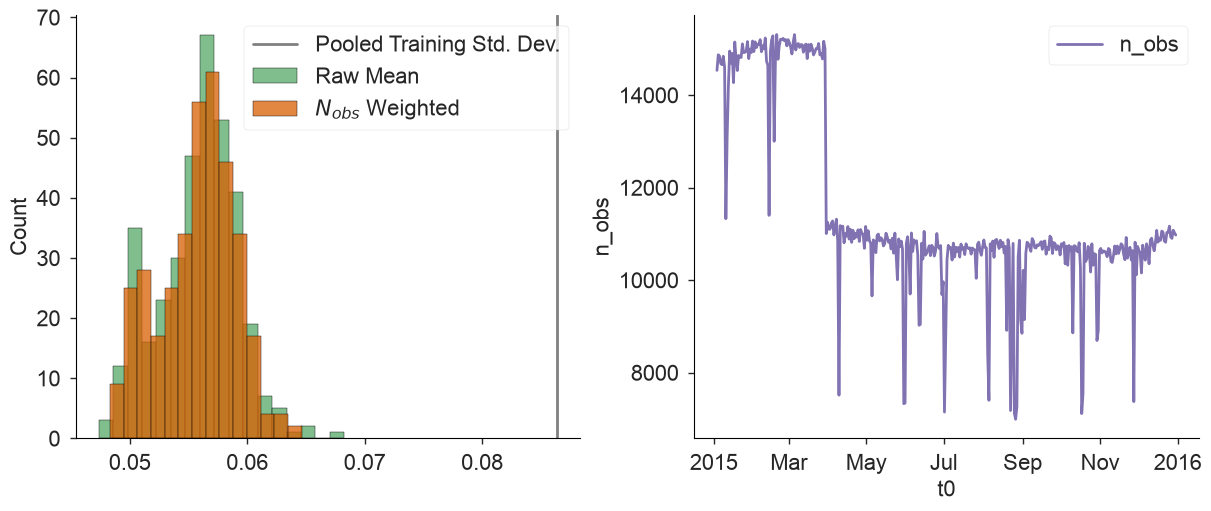

In [71]:
histplot("rmse", show_stdev=True);

(<Figure size 1200x500 with 2 Axes>,
 array([<Axes: ylabel='Count'>, <Axes: xlabel='t0', ylabel='n_obs'>],
       dtype=object))

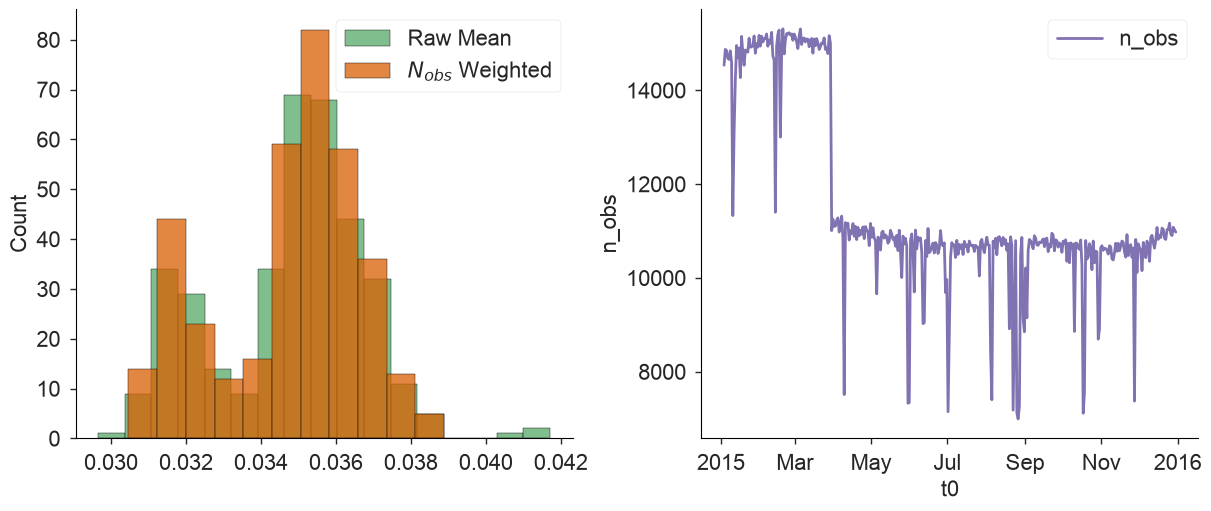

In [72]:
histplot("mae")

In [12]:
gds = xr.open_dataset("runs/v3/metrics/sla.per_group.nc")
gds = gds.squeeze()
gds.load()

<xarray.Dataset> Size: 52kB
Dimensions:     (t0: 362, group: 4)
Coordinates:
  * t0          (t0) datetime64[ns] 3kB 2015-01-03T12:00:00 ... 2015-12-30T12...
    valid_time  (t0) datetime64[ns] 3kB 2015-01-04T12:00:00 ... 2015-12-31T12...
  * group       (group) <U10 160B 'cryosat_2' 'haiyang_2a' 'jason_2' 'saral'
    lead_time   timedelta64[ns] 8B 1 days
    fhr         int64 8B 24
Data variables:
    rmse        (t0, group) float64 12kB 0.05313 0.05508 0.05131 ... 0.06092 nan
    mae         (t0, group) float64 12kB 0.03148 0.03358 0.03227 ... 0.03655 nan
    bias        (t0, group) float64 12kB 0.0001719 0.0003846 ... -0.001312 nan
    n_obs       (group, t0) int64 12kB 3472 3701 3617 3648 3411 ... 0 0 0 0 0

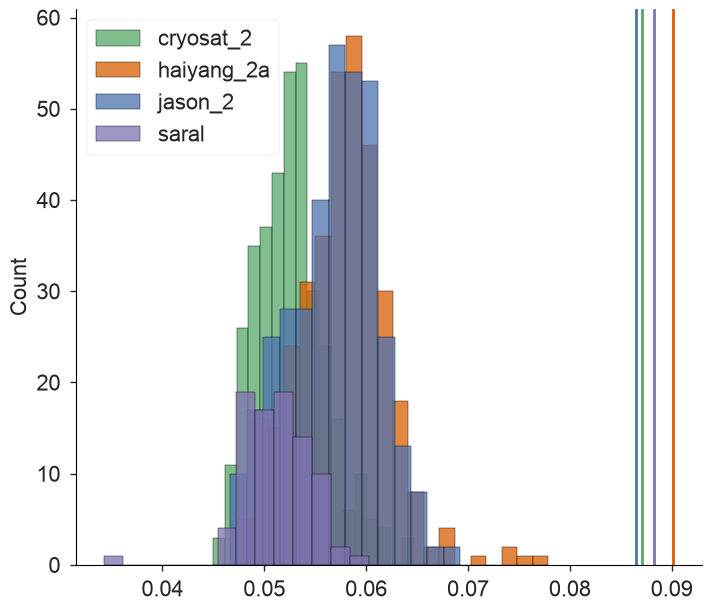

In [75]:
metric = "rmse"

fig, ax = plt.subplots()
for i, group in enumerate(gds.group.values):
    sns.histplot(
        gds[metric].sel(group=group),
        label=group,
        #alpha=.5
        color=f"C{i}",
    )
    ax.axvline(sds["stdev"].sel(variable=f"sla_filtered_{group}"), color=f"C{i}")
ax.legend();

## Observed at input

In [19]:
ods = xr.open_dataset("runs/v3/metrics/sla.by_region.all_groups.nc")
ods = ods.squeeze()
ods.load()

<xarray.Dataset> Size: 75kB
Dimensions:        (t0: 362, region: 3)
Coordinates:
  * t0             (t0) datetime64[ns] 3kB 2015-01-03T12:00:00 ... 2015-12-30...
    valid_time     (t0) datetime64[ns] 3kB 2015-01-04T12:00:00 ... 2015-12-31...
  * region         (region) <U12 144B 'seen_at_t0' 'seen_earlier' 'unseen'
    lead_time      timedelta64[ns] 8B 1 days
    fhr            int64 8B 24
Data variables:
    rmse           (t0, region) float64 9kB 0.04453 0.04925 ... 0.05657 0.07226
    mae            (t0, region) float64 9kB 0.02858 0.03052 ... 0.03345 0.04448
    bias           (t0, region) float64 9kB 0.0006911 -0.0007031 ... -0.002212
    n_live_groups  (t0, region) int64 9kB 4 4 4 4 4 4 4 4 4 ... 3 3 3 3 3 3 3 3
    rmse_pooled    (t0, region) float64 9kB 0.04439 0.04957 ... 0.05732 0.07266
    mae_pooled     (t0, region) float64 9kB 0.02854 0.03061 ... 0.03372 0.04511
    bias_pooled    (t0, region) float64 9kB 0.0005805 -0.0006955 ... -0.00255
    n_obs          (t0, region) int64 9kB 5005 6006 3526 5360 ... 3123 4258 3595

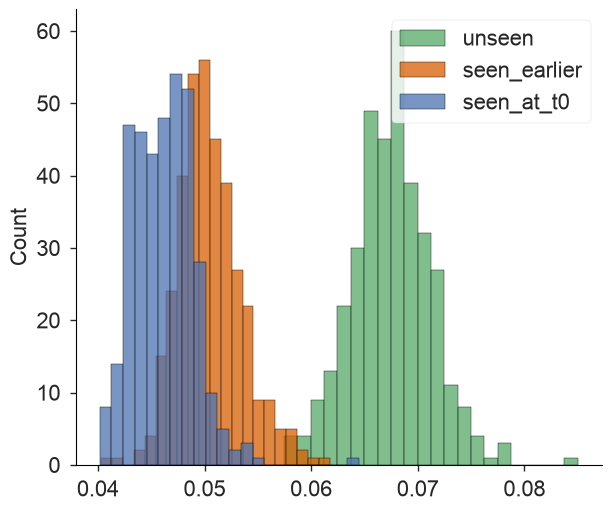

In [26]:
metric = "rmse"

fig, ax = plt.subplots(figsize=(6,5))
for region in ["unseen", "seen_earlier", "seen_at_t0"]:
    sns.histplot(
        ods[metric].sel(region=region),
        label=region,
        #alpha=.5
    )
ax.legend();

In [27]:
ogds = xr.open_dataset("runs/v3/metrics/sla.by_region.per_group.nc")
ogds = ogds.squeeze()
ogds.load()

<xarray.Dataset> Size: 145kB
Dimensions:     (t0: 362, group: 4, region: 3)
Coordinates:
  * t0          (t0) datetime64[ns] 3kB 2015-01-03T12:00:00 ... 2015-12-30T12...
    valid_time  (t0) datetime64[ns] 3kB 2015-01-04T12:00:00 ... 2015-12-31T12...
  * group       (group) <U10 160B 'cryosat_2' 'haiyang_2a' 'jason_2' 'saral'
  * region      (region) <U12 144B 'seen_at_t0' 'seen_earlier' 'unseen'
    lead_time   timedelta64[ns] 8B 1 days
    fhr         int64 8B 24
Data variables:
    rmse        (t0, group, region) float64 35kB 0.045 0.05515 ... nan nan
    mae         (t0, group, region) float64 35kB 0.02793 0.03257 ... nan nan
    bias        (t0, group, region) float64 35kB 0.001829 6.203e-05 ... nan nan
    n_obs       (group, t0, region) int64 35kB 1172 1724 576 1244 ... 0 0 0 0

In [30]:
ogds[metric].sel(region=region)

<xarray.DataArray 'rmse' (t0: 362, group: 4)> Size: 12kB
array([[0.06158056, 0.07550271, 0.06856218, 0.06544692],
       [0.05472804, 0.07185566, 0.06365882, 0.06876873],
       [0.04963029, 0.07609925, 0.07472235, 0.07322436],
       ...,
       [0.06619109, 0.07605465, 0.07418056,        nan],
       [0.05749423, 0.06967148, 0.07667107,        nan],
       [0.06936631, 0.07077028, 0.07645413,        nan]], shape=(362, 4))
Coordinates:
  * t0          (t0) datetime64[ns] 3kB 2015-01-03T12:00:00 ... 2015-12-30T12...
    valid_time  (t0) datetime64[ns] 3kB 2015-01-04T12:00:00 ... 2015-12-31T12...
  * group       (group) <U10 160B 'cryosat_2' 'haiyang_2a' 'jason_2' 'saral'
    lead_time   timedelta64[ns] 8B 1 days
    fhr         int64 8B 24
    region      <U12 48B 'unseen'
Attributes:
    fill_value:  nan

In [88]:
def make_it_nice(ax):
    ax.set(
        xlabel="",
        ylabel=ax.get_ylabel().upper(),
        xticklabels=[x.get_text().replace("_"," ").capitalize() for x in ax.get_xticklabels()],
    )

['cryosat_2' 'haiyang_2a' 'jason_2' 'saral']


/var/folders/0k/gh0lwxg17l1_fbtvplvt45s40000gp/T/ipykernel_8006/1547974153.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set(


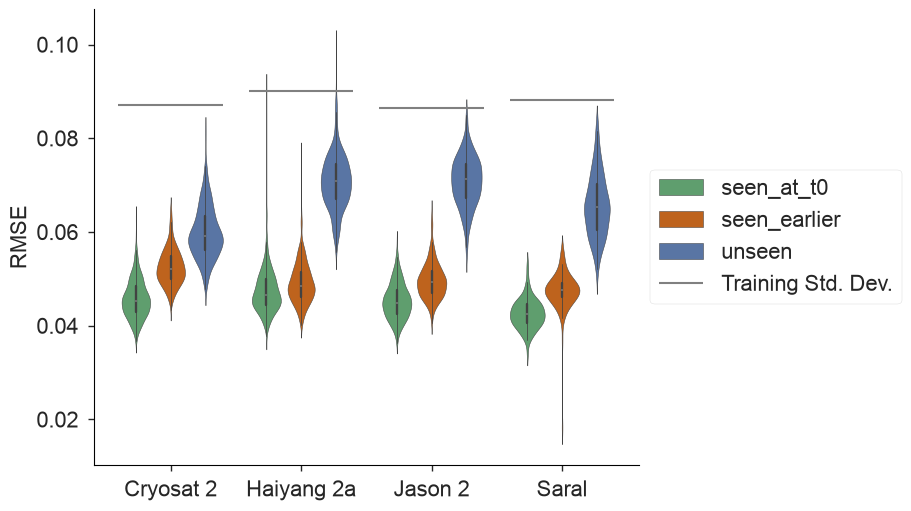

In [91]:
metric = "rmse"

fig, ax = plt.subplots(figsize=(9,5))
df = ogds[metric].to_dataset().to_dataframe().reset_index()
sns.violinplot(
    df,
    y="rmse",
    x="group",
    #alpha=.5
    hue="region",
)

groups = ogds["group"].values
stdev = sds["stdev"].sel(variable=[f"sla_filtered_{g}" for g in groups]).values
print(groups)
x = np.arange(len(groups))

ax.hlines(stdev, x - 0.4, x + 0.4, color="gray", lw=1.5, zorder=3,
          label="Training Std. Dev.")
    
l = ax.legend(bbox_to_anchor=(1., .5), loc="center left");

make_it_nice(ax)